<a href="https://colab.research.google.com/github/shrutikushwaha2110-ux/Facial-Expression-Recognition-CNN/blob/exp%2Ftransfer-learning/notebooks/04_transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np

!unzip fer2013_preprocessed.npz.zip

Archive:  fer2013_preprocessed.npz.zip
  inflating: X_train.npy             
  inflating: y_train.npy             
  inflating: X_val.npy               
  inflating: y_val.npy               
  inflating: X_test.npy              
  inflating: y_test.npy              


In [3]:
import numpy as np

# Load the 6 individual .npy files directly from your workspace
X_train = np.load("X_train.npy")
y_train = np.load("y_train.npy")
X_val = np.load("X_val.npy")
y_val = np.load("y_val.npy")
X_test = np.load("X_test.npy")
y_test = np.load("y_test.npy")

print("Successfully loaded team's data from individual files!")
print(f"X_train shape: {X_train.shape}")
print(f"X_val shape:   {X_val.shape}")
print(f"X_test shape:  {X_test.shape}")

Successfully loaded team's data from individual files!
X_train shape: (22949, 48, 48, 1)
X_val shape:   (5749, 48, 48, 1)
X_test shape:  (7178, 48, 48, 1)


Preparing and resizing datasets...
Computed Class Weights: {0: np.float64(1.0273984868155974), 1: np.float64(9.447920955125566), 2: np.float64(0.9989118133542265), 3: np.float64(0.5678899309593922), 4: np.float64(0.8499944442386755), 5: np.float64(1.298901969662667), 6: np.float64(0.8247619047619048)}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 48, 48,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 48, 48,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 48, 48,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 48, 48,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 48, 48,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 48, 48,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 48, 48,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 48, 48,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 49, 49,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 24, 24,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 24, 24,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 24, 24,    │      2,304 │ block_1_depthwis

 Total params: 2,587,719 (9.87 MB)

 Trainable params: 329,735 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 35s 58ms/step - accuracy: 0.2953 - loss: 1.7825 - val_accuracy: 0.3919 - val_loss: 1.5755
Epoch 2/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.3581 - loss: 1.6240 - val_accuracy: 0.4121 - val_loss: 1.5560
Epoch 3/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.3824 - loss: 1.5365 - val_accuracy: 0.4321 - val_loss: 1.4877
Epoch 4/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.3999 - loss: 1.4959 - val_accuracy: 0.4309 - val_loss: 1.5036
Epoch 5/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4130 - loss: 1.4624 - val_accuracy: 0.4448 - val_loss: 1.4722
Epoch 6/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4233 - loss: 1.4305 - val_accuracy: 0.4576 - val_loss: 1.4408
Epoch 7/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4353 - loss: 1.3839 - val_accuracy: 0.4622 - val_loss: 1.3951
Epoch 8/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.4367 - loss: 1.3559 - val_ac

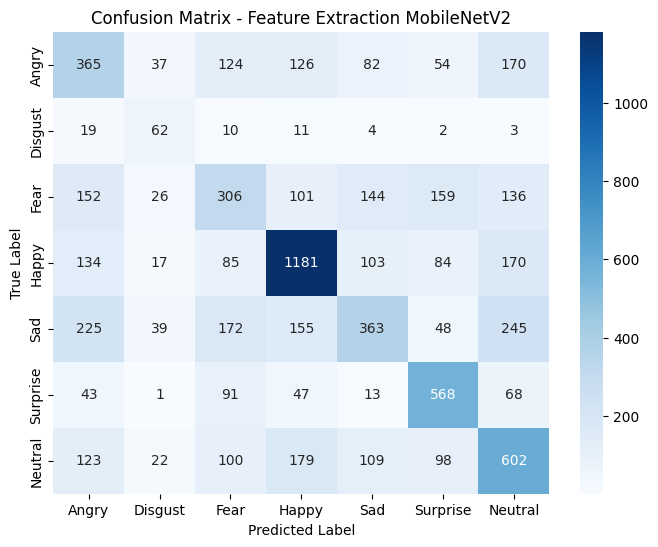

Feature extraction confusion matrix saved to confusion_matrix_feature_extraction.png


In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Resize and prepare datasets for MobileNetV2 (_mb)
def prepare_mb_data(X):
    X_resized = tf.image.resize(X, (96, 96))
    X_rgb = tf.repeat(X_resized, repeats=3, axis=-1)
    # Scale from [0, 1] to [-1, 1] expected by MobileNetV2
    X_rgb = X_rgb * 2.0 - 1.0
    return X_rgb

print("Preparing and resizing datasets...")
X_train_mb = prepare_mb_data(X_train)
X_val_mb = prepare_mb_data(X_val)
X_test_mb = prepare_mb_data(X_test)

# Compute balanced class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = dict(enumerate(class_weights))
print("Computed Class Weights:", class_weights_dict)

# 2. Load MobileNetV2 base without top layers
base_model = MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze base layers first

# 3. Attach custom classification head using the Functional API
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
output_layer = Dense(7, activation='softmax')(x) # 7 emotion classes

model = Model(inputs=base_model.input, outputs=output_layer)

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# 4. Train classification head with class weighting
history_head = model.fit(
    X_train_mb, y_train,
    validation_data=(X_val_mb, y_val),
    epochs=10,
    batch_size=64,
    class_weight=class_weights_dict
)

# 5. Evaluate Feature Extraction Model on Test Set (All 5 metrics)
print("\n--- Feature Extraction Test Evaluation ---");
fe_test_loss, fe_test_accuracy = model.evaluate(X_test_mb, y_test, verbose=0)
y_pred_fe_probs = model.predict(X_test_mb)
y_pred_fe = np.argmax(y_pred_fe_probs, axis=1)

fe_macro_precision = precision_score(y_test, y_pred_fe, average='macro', zero_division=0)
fe_macro_recall = recall_score(y_test, y_pred_fe, average='macro', zero_division=0)
fe_macro_f1 = f1_score(y_test, y_pred_fe, average='macro', zero_division=0)

print(f"Feature Extraction Test Loss:      {fe_test_loss:.4f}")
print(f"Feature Extraction Test Accuracy:  {fe_test_accuracy * 100:.2f}%")
print(f"Feature Extraction Macro Precision:{fe_macro_precision:.4f}")
print(f"Feature Extraction Macro Recall:   {fe_macro_recall:.4f}")
print(f"Feature Extraction Macro F1 Score: {fe_macro_f1:.4f}")

# Classification Report & Save to file
emotion_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
fe_class_report_str = classification_report(y_test, y_pred_fe, target_names=emotion_labels, zero_division=0)
print("\nFeature Extraction Classification Report:\n", fe_class_report_str)

with open('classification_report_feature_extraction.txt', 'w') as f:
    f.write(fe_class_report_str)
print("Feature extraction classification report saved to classification_report_feature_extraction.txt")

# Save and Plot Confusion Matrix for Feature Extraction
plt.figure(figsize=(8, 6))
cm_fe = confusion_matrix(y_test, y_pred_fe)
sns.heatmap(cm_fe, annot=True, fmt='d', cmap='Blues', xticklabels=emotion_labels, yticklabels=emotion_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Feature Extraction MobileNetV2')
plt.savefig('confusion_matrix_feature_extraction.png', bbox_inches='tight')
plt.show()
print("Feature extraction confusion matrix saved to confusion_matrix_feature_extraction.png")

Batch Normalization layers successfully frozen for fine-tuning.
Starting fine-tuning with Early Stopping (patience=5) and Class Weights...
Epoch 1/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 36s 63ms/step - accuracy: 0.3813 - loss: 1.5574 - val_accuracy: 0.4486 - val_loss: 1.4672 - learning_rate: 1.0000e-04
Epoch 2/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.4469 - loss: 1.4083 - val_accuracy: 0.4822 - val_loss: 1.3681 - learning_rate: 1.0000e-04
Epoch 3/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.4880 - loss: 1.2779 - val_accuracy: 0.4743 - val_loss: 1.3967 - learning_rate: 1.0000e-04
Epoch 4/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.5043 - loss: 1.2115 - val_accuracy: 0.4771 - val_loss: 1.3968 - learning_rate: 1.0000e-04
Epoch 5/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.5602 - loss: 1.0461 - val_accuracy: 0.5309 - val_loss: 1.2554 - learning_rate: 5.0000e-05
Epoch 6/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.5853 - l

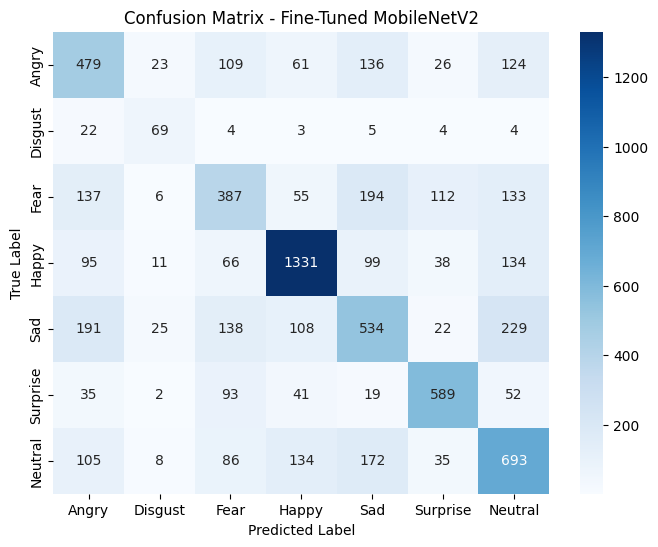

Confusion matrix saved to confusion_matrix.png
Model saved successfully!


In [5]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Unfreeze the MobileNetV2 base model for fine-tuning
base_model.trainable = True

# Keep lower layers frozen, fine-tune only the top 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# CRITICAL: Keep Batch Normalization layers frozen to prevent overfitting
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Batch Normalization layers successfully frozen for fine-tuning.")

# 2. Recompile with a low learning rate
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Set up smart restrictions (Callbacks) - Patience = 5 consistent with README
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,               # Stop if val_loss doesn't improve for 5 epochs
    restore_best_weights=True # Keep the weights from the absolute best epoch
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,               # Cut learning rate in half if it plateaus
    patience=2,               # Wait 2 epochs before reducing LR
    min_lr=0.00001
)

print("Starting fine-tuning with Early Stopping (patience=5) and Class Weights...")
# 4. Fine-tune for up to 15 epochs with class weights
history_fine = model.fit(
    X_train_mb, y_train,
    validation_data=(X_val_mb, y_val),
    epochs=15,
    batch_size=64,
    class_weight=class_weights_dict,
    callbacks=[early_stopping, reduce_lr]
)

# 5. Evaluate Fine-Tuned Model on Test Set (All 5 metrics)
print("\n--- Fine-Tuning Test Evaluation ---");
test_loss, test_accuracy = model.evaluate(X_test_mb, y_test, verbose=0)
y_pred_probs = model.predict(X_test_mb)
y_pred = np.argmax(y_pred_probs, axis=1)

macro_precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
macro_recall = recall_score(y_test, y_pred, average='macro', zero_division=0)
macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

print(f"Fine-Tuning Test Loss:      {test_loss:.4f}")
print(f"Fine-Tuning Test Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Fine-Tuning Macro Precision:{macro_precision:.4f}")
print(f"Fine-Tuning Macro Recall:   {macro_recall:.4f}")
print(f"Fine-Tuning Macro F1 Score: {macro_f1:.4f}")

# Classification Report & Save to file
emotion_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
class_report_str = classification_report(y_test, y_pred, target_names=emotion_labels, zero_division=0)
print("\nClassification Report:\n", class_report_str)

with open('classification_report.txt', 'w') as f:
    f.write(class_report_str)
print("Classification report saved to classification_report.txt")

# 6. Save and Plot Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=emotion_labels, yticklabels=emotion_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Fine-Tuned MobileNetV2')
plt.savefig('confusion_matrix.png', bbox_inches='tight')
plt.show()
print("Confusion matrix saved to confusion_matrix.png")

# 7. Save final model
model.save('fer2013_mobilenet_finetuned_best.keras')
print("Model saved successfully!")